# Data Quality — Home Credit Application Data

In [56]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

DATA_PATH = Path("data.csv")
OUTPUT_DIR = Path("output") / "data_quality"
FIGURE_DIR = OUTPUT_DIR / "figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Expected the application data at {DATA_PATH.resolve()}.")

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_rows", 80)
pd.set_option("display.float_format", lambda value: f"{value:,.6f}")

df = pd.read_csv(DATA_PATH)
print(f"Loaded {len(df):,} applications and {df.shape[1]} fields.")

Loaded 307,511 applications and 122 fields.


## 1. Overall Missingness Profiling

In [57]:
missingness = pd.DataFrame({
    "missing": df.isna().sum(),
    "missing_proportion": df.isna().mean(),
})
missingness = (
    missingness[missingness["missing"].gt(0)]
    .sort_values(["missing_proportion", "missing"], ascending=False)
)
missingness.index.name = "column"

assert len(missingness) == 67
display(missingness)
missingness.to_csv(OUTPUT_DIR / "missingness_67.csv")
print(f"{len(missingness)} fields have at least one missing value.")

,missing,missing_proportion
column,,
COMMONAREA_AVG,214865,0.698723
COMMONAREA_MODE,214865,0.698723
COMMONAREA_MEDI,214865,0.698723
NONLIVINGAPARTMENTS_AVG,213514,0.694330
NONLIVINGAPARTMENTS_MODE,213514,0.694330
NONLIVINGAPARTMENTS_MEDI,213514,0.694330
FONDKAPREMONT_MODE,210295,0.683862
LIVINGAPARTMENTS_AVG,210199,0.683550
LIVINGAPARTMENTS_MODE,210199,0.683550


67 fields have at least one missing value.


## 2. Missingness Pattern and Mechanism

This section uses the 21 fields that are kept in the model and are either missing or coded with a sentinel treated as missing. `DAYS_EMPLOYED = 365243` and `ORGANIZATION_TYPE = "XNA"` are set to missing before the rates and tests. Gender labels, age bands, and income quartiles match the profiling notebook.

### 2.1 Missing Rate by Gender, Age Band, Income, and Default

In [58]:
import numpy as np

RETAINED_MISSING = [
    "EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3",
    "OCCUPATION_TYPE", "NAME_TYPE_SUITE",
    "AMT_REQ_CREDIT_BUREAU_HOUR", "AMT_REQ_CREDIT_BUREAU_DAY",
    "AMT_REQ_CREDIT_BUREAU_WEEK", "AMT_REQ_CREDIT_BUREAU_MON",
    "AMT_REQ_CREDIT_BUREAU_QRT", "AMT_REQ_CREDIT_BUREAU_YEAR",
    "OBS_30_CNT_SOCIAL_CIRCLE", "DEF_30_CNT_SOCIAL_CIRCLE",
    "OBS_60_CNT_SOCIAL_CIRCLE", "DEF_60_CNT_SOCIAL_CIRCLE",
    "AMT_GOODS_PRICE", "AMT_ANNUITY", "CNT_FAM_MEMBERS",
    "DAYS_LAST_PHONE_CHANGE", "DAYS_EMPLOYED", "ORGANIZATION_TYPE",
]
AGE_BANDS = ["<25", "25–34", "35–44", "45–54", "55–64", "65+"]
GENDERS = ["Female", "Male"]
INCOME_BANDS = ["Q1 low", "Q2", "Q3", "Q4 high"]
DEFAULT_GROUPS = ["Non-default", "Default"]

missing_retained = [column for column in RETAINED_MISSING if column not in df.columns]
if missing_retained:
    raise ValueError(f"Missing retained fields: {missing_retained}")

analysis = df.loc[
    ~df["CODE_GENDER"].eq("XNA") & ~df["NAME_FAMILY_STATUS"].eq("Unknown")
].copy()
analysis["gender"] = analysis["CODE_GENDER"].map({"F": "Female", "M": "Male"})
analysis["age_years"] = -analysis["DAYS_BIRTH"] / 365.25
analysis["age_band"] = pd.cut(
    analysis["age_years"],
    bins=[0, 25, 35, 45, 55, 65, np.inf],
    labels=AGE_BANDS,
    right=False,
).astype("string")
income_quartiles = analysis["AMT_INCOME_TOTAL"].quantile([0.25, 0.50, 0.75]).to_numpy()
analysis["income_band"] = pd.cut(
    analysis["AMT_INCOME_TOTAL"],
    bins=[-np.inf, *income_quartiles, np.inf],
    labels=INCOME_BANDS,
    include_lowest=True,
).astype("string")
analysis["default_status"] = analysis["TARGET"].map({0: "Non-default", 1: "Default"})
analysis["DAYS_EMPLOYED"] = analysis["DAYS_EMPLOYED"].replace(365243, np.nan)
analysis["ORGANIZATION_TYPE"] = analysis["ORGANIZATION_TYPE"].replace("XNA", np.nan)

overall_rate = analysis[RETAINED_MISSING].isna().mean().rename("overall").rename_axis("column").reset_index()
retained_missing = (
    overall_rate.sort_values(["overall", "column"], ascending=[False, True])["column"].tolist()
)

def show_group_rates(title, group_name, levels):
    rows = []
    for feature in retained_missing:
        missing = analysis[feature].isna()
        row = {"n_missing": int(missing.sum()), "overall": float(missing.mean())}
        for level in levels:
            row[level] = float(missing[analysis[group_name].eq(level)].mean())
        rows.append(row)
    table = pd.DataFrame(rows, index=retained_missing)
    table.index.name = "column"
    display(table)

    slug = title.lower().replace(" ", "_")
    table.to_csv(OUTPUT_DIR / f"missingness_rates_by_{slug}.csv")

    rate_matrix = table[list(levels)]
    fig, ax = plt.subplots(figsize=(max(7, 1.15 * len(levels) + 4), 8))
    image = ax.imshow(rate_matrix.to_numpy(), aspect="auto", cmap="YlOrRd", vmin=0, vmax=1)
    rotation = 0 if len(levels) <= 4 else 30
    ax.set_xticks(range(len(levels)))
    ax.set_xticklabels(list(levels), rotation=rotation, ha="center" if rotation == 0 else "right")
    ax.set_yticks(range(len(rate_matrix)))
    ax.set_yticklabels(rate_matrix.index)
    ax.set_title(f"Missing rate by {title.lower()}")
    for row_index, feature in enumerate(rate_matrix.index):
        for column_index, level in enumerate(levels):
            value = rate_matrix.loc[feature, level]
            ax.text(
                column_index,
                row_index,
                f"{value:.1%}",
                ha="center",
                va="center",
                fontsize=8,
                color="white" if value >= 0.45 else "black",
            )
    fig.colorbar(image, ax=ax, label="Proportion missing")
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / f"missingness_rates_by_{slug}.png", dpi=160, bbox_inches="tight")
    plt.show()

#### Gender

,n_missing,overall,Female,Male
column,,,,
EXT_SOURCE_1,173375,0.563812,0.547338,0.595557
OCCUPATION_TYPE,96389,0.313455,0.361408,0.221049
EXT_SOURCE_3,60964,0.198254,0.190731,0.212749
DAYS_EMPLOYED,55374,0.180075,0.223619,0.096166
ORGANIZATION_TYPE,55374,0.180075,0.223619,0.096166
AMT_REQ_CREDIT_BUREAU_DAY,41518,0.135016,0.129338,0.145957
AMT_REQ_CREDIT_BUREAU_HOUR,41518,0.135016,0.129338,0.145957
AMT_REQ_CREDIT_BUREAU_MON,41518,0.135016,0.129338,0.145957
AMT_REQ_CREDIT_BUREAU_QRT,41518,0.135016,0.129338,0.145957


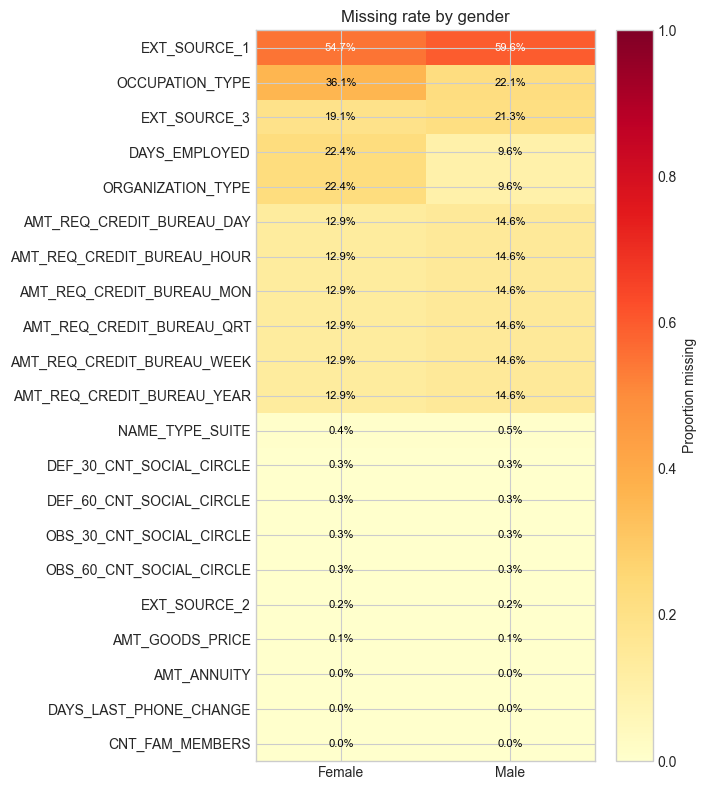

In [59]:
show_group_rates("Gender", "gender", GENDERS)

#### Age band

,n_missing,overall,<25,25–34,35–44,45–54,55–64,65+
column,,,,,,,,
EXT_SOURCE_1,173375,0.563812,0.448459,0.411109,0.490630,0.632968,0.754598,0.847765
OCCUPATION_TYPE,96389,0.313455,0.175100,0.167205,0.165680,0.229776,0.739677,0.924708
EXT_SOURCE_3,60964,0.198254,0.344642,0.215185,0.178070,0.188674,0.183969,0.226257
DAYS_EMPLOYED,55374,0.180075,0.002779,0.003659,0.011607,0.079157,0.684985,0.899568
ORGANIZATION_TYPE,55374,0.180075,0.002779,0.003659,0.011607,0.079157,0.684985,0.899568
AMT_REQ_CREDIT_BUREAU_DAY,41518,0.135016,0.275730,0.148690,0.112629,0.130631,0.125411,0.143093
AMT_REQ_CREDIT_BUREAU_HOUR,41518,0.135016,0.275730,0.148690,0.112629,0.130631,0.125411,0.143093
AMT_REQ_CREDIT_BUREAU_MON,41518,0.135016,0.275730,0.148690,0.112629,0.130631,0.125411,0.143093
AMT_REQ_CREDIT_BUREAU_QRT,41518,0.135016,0.275730,0.148690,0.112629,0.130631,0.125411,0.143093


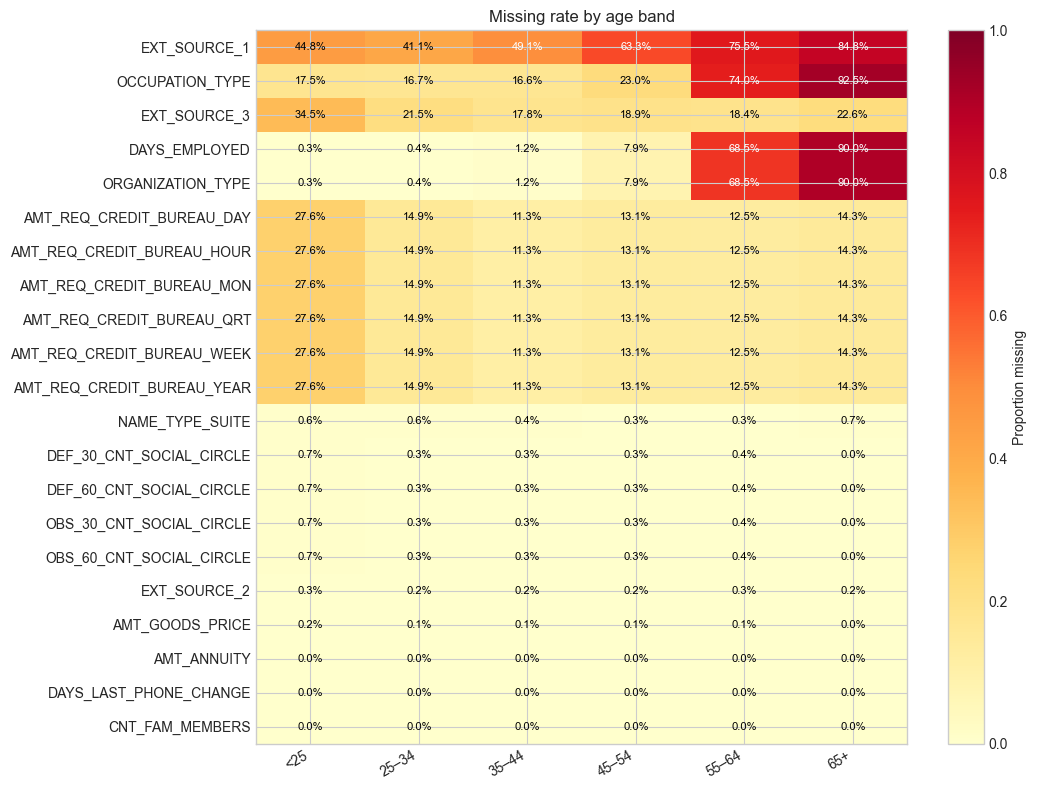

In [60]:
show_group_rates("Age band", "age_band", AGE_BANDS)

#### Income

,n_missing,overall,Q1 low,Q2,Q3,Q4 high
column,,,,,,
EXT_SOURCE_1,173375,0.563812,0.611018,0.567345,0.545997,0.515286
OCCUPATION_TYPE,96389,0.313455,0.389012,0.307798,0.279135,0.250870
EXT_SOURCE_3,60964,0.198254,0.239645,0.201162,0.180000,0.158873
DAYS_EMPLOYED,55374,0.180075,0.272048,0.174950,0.138181,0.102719
ORGANIZATION_TYPE,55374,0.180075,0.272048,0.174950,0.138181,0.102719
AMT_REQ_CREDIT_BUREAU_DAY,41518,0.135016,0.170594,0.137380,0.119522,0.101041
AMT_REQ_CREDIT_BUREAU_HOUR,41518,0.135016,0.170594,0.137380,0.119522,0.101041
AMT_REQ_CREDIT_BUREAU_MON,41518,0.135016,0.170594,0.137380,0.119522,0.101041
AMT_REQ_CREDIT_BUREAU_QRT,41518,0.135016,0.170594,0.137380,0.119522,0.101041


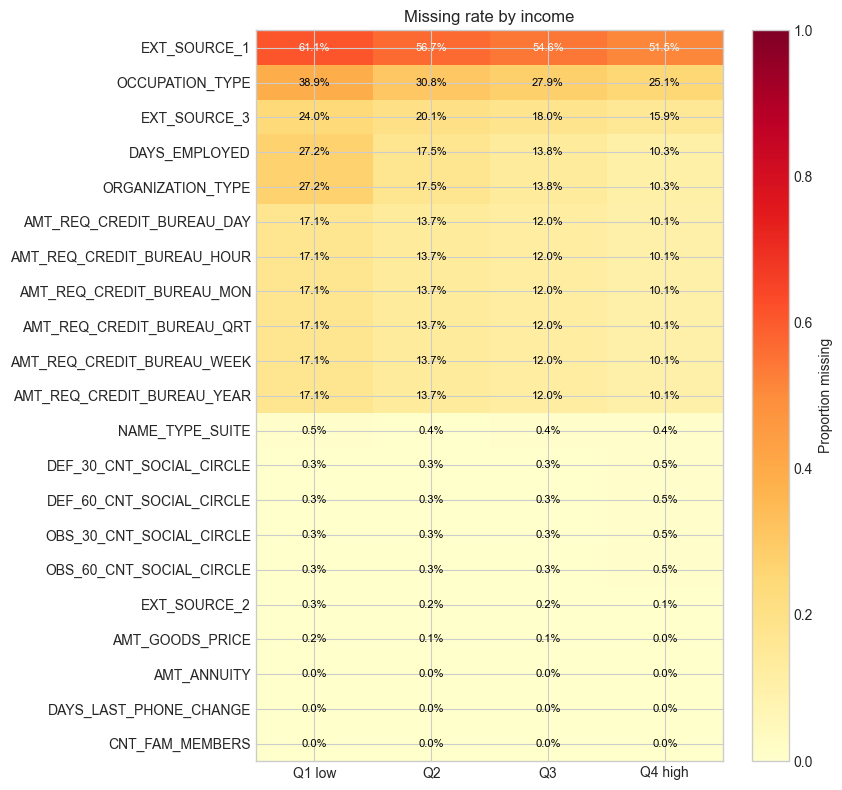

In [61]:
show_group_rates("Income", "income_band", INCOME_BANDS)

#### Default

,n_missing,overall,Non-default,Default
column,,,,
EXT_SOURCE_1,173375,0.563812,0.561073,0.595005
OCCUPATION_TYPE,96389,0.313455,0.318774,0.252890
EXT_SOURCE_3,60964,0.198254,0.195582,0.228681
DAYS_EMPLOYED,55374,0.180075,0.185312,0.120443
ORGANIZATION_TYPE,55374,0.180075,0.185312,0.120443
AMT_REQ_CREDIT_BUREAU_DAY,41518,0.135016,0.131690,0.172890
AMT_REQ_CREDIT_BUREAU_HOUR,41518,0.135016,0.131690,0.172890
AMT_REQ_CREDIT_BUREAU_MON,41518,0.135016,0.131690,0.172890
AMT_REQ_CREDIT_BUREAU_QRT,41518,0.135016,0.131690,0.172890


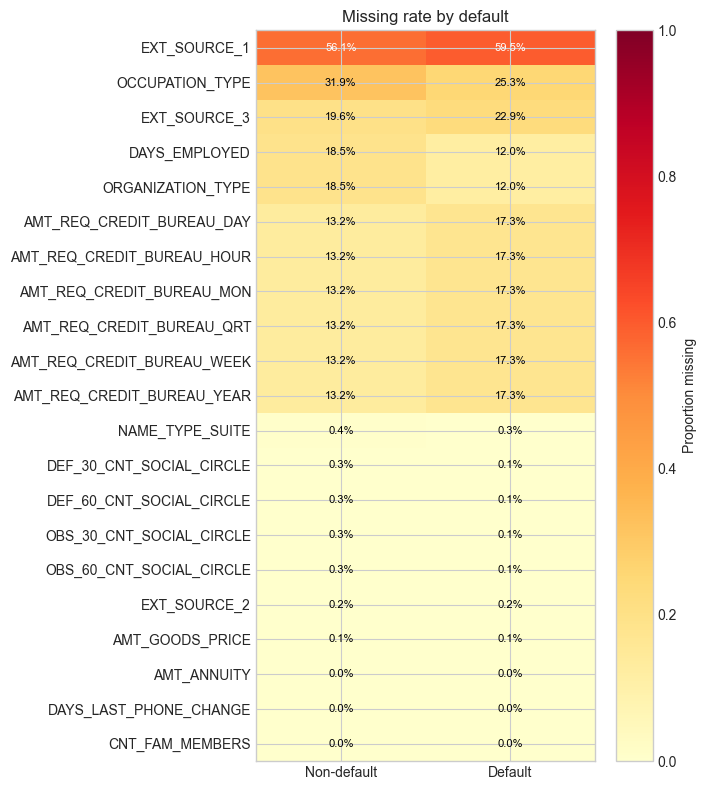

In [62]:
show_group_rates("Default", "default_status", DEFAULT_GROUPS)

### 2.2 Association With Gender, Age, Income, and Default

Chi-square tests missingness against gender, age band, income band, and default one at a time. Logistic regression then fits missingness on male, age in years, income band, and default together. The male odds ratio compares men with women. The default odds ratio compares defaults with non-defaults. The age odds ratio is for one additional year of age. The income odds ratios compare Q2, Q3, and Q4 high with Q1 low.

Logistic models are fit only when a field has at least 30 missing values. p-values are not adjusted for the number of tests. A small rate difference can still have a very small p-value at this sample size, so the rate difference and Cramer's V show the size of the association. A chi-square test with a minimum expected count below 5 is not reliable.

`rate_difference` is the gap in the missing rate, in percentage points:

- Gender: Male − Female
- Age band: higher missing-rate band − lower missing-rate band
- Income: higher missing-rate band − lower missing-rate band
- Default: Default − Non-default

For age and income, the contrast names the two bands in that order.

In [63]:
from IPython.display import HTML
from scipy.stats import chi2_contingency

def cramers_v(chi2, table):
    n_observations = table.to_numpy().sum()
    n_rows, n_cols = table.shape
    return np.sqrt(chi2 / (n_observations * min(n_rows - 1, n_cols - 1)))

def group_rates(feature, group_name, levels):
    missing = analysis[feature].isna()
    return pd.Series({
        level: float(missing[analysis[group_name].eq(level)].mean())
        for level in levels
    })

chi_rows = []
comparisons = [
    ("Gender", "gender", GENDERS, "Male - Female", lambda rates: rates["Male"] - rates["Female"]),
    ("Age band", "age_band", AGE_BANDS, None, None),
    ("Income", "income_band", INCOME_BANDS, None, None),
    ("Default", "default_status", DEFAULT_GROUPS, "Default - Non-default", lambda rates: rates["Default"] - rates["Non-default"]),
]
for feature in retained_missing:
    n_missing = int(analysis[feature].isna().sum())
    if n_missing == 0:
        for grouping, *_ in comparisons:
            chi_rows.append({
                "feature": feature,
                "grouping": grouping,
                "n_missing": 0,
                "contrast": "",
                "rate_difference": np.nan,
                "chi2": np.nan,
                "dof": np.nan,
                "p_value": np.nan,
                "cramers_v": np.nan,
                "min_expected": np.nan,
            })
        continue
    for grouping, group_name, levels, contrast, difference in comparisons:
        rates = group_rates(feature, group_name, levels)
        if difference is None:
            higher = rates.idxmax()
            lower = rates.idxmin()
            contrast = f"{higher} - {lower}"
            rate_difference = float(rates[higher] - rates[lower])
        else:
            rate_difference = float(difference(rates))
        table = pd.crosstab(analysis[feature].isna(), analysis[group_name])
        chi2, p_value, dof, expected = chi2_contingency(table)
        chi_rows.append({
            "feature": feature,
            "grouping": grouping,
            "n_missing": n_missing,
            "contrast": contrast,
            "rate_difference": rate_difference,
            "chi2": float(chi2),
            "dof": int(dof),
            "p_value": float(p_value),
            "cramers_v": float(cramers_v(chi2, table)),
            "min_expected": float(expected.min()),
        })

chi_square = pd.DataFrame(chi_rows).set_index(["feature", "grouping"])
chi_square_report = chi_square.reset_index()
chi_square_report["conclusion"] = np.where(
    chi_square_report["min_expected"].lt(5) | chi_square_report["p_value"].isna(),
    "not_reliable",
    np.where(chi_square_report["p_value"].lt(0.05), "h1_associated", "h0_not_associated"),
)
chi_square_report["rate_difference"] = chi_square_report["rate_difference"].map(
    lambda value: "" if pd.isna(value) else f"{value * 100:.2f}%"
)
chi_square_report["cramers_v"] = chi_square_report["cramers_v"].map(
    lambda value: "" if pd.isna(value) else value
)
chi_square_report = chi_square_report[[
    "feature", "grouping", "n_missing", "conclusion", "cramers_v", "rate_difference"
]]
chi_square_report.to_csv(OUTPUT_DIR / "missingness_chi_square.csv", index=False)
display(HTML("<b>CHI-SQUARE TEST</b>" + chi_square_report.to_html(index=False)))

feature,grouping,n_missing,conclusion,cramers_v,rate_difference
EXT_SOURCE_1,Gender,173375,h1_associated,0.046106,4.82%
EXT_SOURCE_1,Age band,173375,h1_associated,0.269105,43.67%
EXT_SOURCE_1,Income,173375,h1_associated,0.074465,9.57%
EXT_SOURCE_1,Default,173375,h1_associated,0.018628,3.39%
OCCUPATION_TYPE,Gender,96389,h1_associated,0.143487,-14.04%
OCCUPATION_TYPE,Age band,96389,h1_associated,0.522294,75.90%
OCCUPATION_TYPE,Income,96389,h1_associated,0.119999,13.81%
OCCUPATION_TYPE,Default,96389,h1_associated,0.038677,-6.59%
EXT_SOURCE_3,Gender,60964,h1_associated,0.026183,2.20%
EXT_SOURCE_3,Age band,60964,h1_associated,0.083673,16.66%


For each retained field, $M=1$ when the value is missing:

$$
\log\left(\frac{P(M=1)}{1-P(M=1)}\right)
= \beta_0
+ \beta_{\mathrm{male}}\mathrm{Male}
+ \beta_{\mathrm{age}}\mathrm{Age}
+ \beta_{Q2}I_{Q2}
+ \beta_{Q3}I_{Q3}
+ \beta_{Q4}I_{Q4}
+ \beta_{\mathrm{default}}\mathrm{Default}
$$

Male is 1 for men and 0 for women. Age is in years. $I_{Q2}$, $I_{Q3}$, and $I_{Q4}$ are indicators for those income quartiles, with Q1 low as the reference. Default is 1 for a default and 0 otherwise. The table reports $e^{\beta}$.

In [64]:
import warnings

import statsmodels.api as sm

MIN_LOGIT_MISSING = 30

def association_label(p_value):
    if pd.isna(p_value):
        return ""
    if p_value < 0.05:
        return "h1_associated"
    return "h0_not_associated"

logit_rows = []
design = sm.add_constant(pd.DataFrame({
    "male": analysis["gender"].eq("Male").astype(float),
    "age_years": analysis["age_years"].astype(float),
    "income_q2": analysis["income_band"].eq("Q2").astype(float),
    "income_q3": analysis["income_band"].eq("Q3").astype(float),
    "income_q4": analysis["income_band"].eq("Q4 high").astype(float),
    "default": analysis["TARGET"].astype(float),
}), has_constant="add")
for feature in retained_missing:
    n_missing = int(analysis[feature].isna().sum())
    row = {
        "n_missing": n_missing,
        "odds_ratio_male": np.nan,
        "p_male": np.nan,
        "odds_ratio_age_per_year": np.nan,
        "p_age": np.nan,
        "odds_ratio_income_q2": np.nan,
        "p_income_q2": np.nan,
        "odds_ratio_income_q3": np.nan,
        "p_income_q3": np.nan,
        "odds_ratio_income_q4": np.nan,
        "p_income_q4": np.nan,
        "odds_ratio_default": np.nan,
        "p_default": np.nan,
    }
    if n_missing >= MIN_LOGIT_MISSING:
        try:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                result = sm.Logit(analysis[feature].isna().astype(int), design).fit(
                    disp=False, maxiter=200, method="lbfgs"
                )
            converged = bool(result.mle_retvals.get("converged", False))
            odds_ratios = np.exp(result.params)
            if converged and np.isfinite(odds_ratios.drop(labels="const")).all():
                row.update({
                    "odds_ratio_male": float(odds_ratios["male"]),
                    "p_male": float(result.pvalues["male"]),
                    "odds_ratio_age_per_year": float(odds_ratios["age_years"]),
                    "p_age": float(result.pvalues["age_years"]),
                    "odds_ratio_income_q2": float(odds_ratios["income_q2"]),
                    "p_income_q2": float(result.pvalues["income_q2"]),
                    "odds_ratio_income_q3": float(odds_ratios["income_q3"]),
                    "p_income_q3": float(result.pvalues["income_q3"]),
                    "odds_ratio_income_q4": float(odds_ratios["income_q4"]),
                    "p_income_q4": float(result.pvalues["income_q4"]),
                    "odds_ratio_default": float(odds_ratios["default"]),
                    "p_default": float(result.pvalues["default"]),
                })
        except Exception:
            pass
    logit_rows.append(row)

logit_results = pd.DataFrame(logit_rows, index=retained_missing)
logit_results.index.name = "feature"
for p_column, conclusion_column in {
    "p_male": "male",
    "p_age": "age",
    "p_income_q2": "income_q2",
    "p_income_q3": "income_q3",
    "p_income_q4": "income_q4",
    "p_default": "default",
}.items():
    logit_results[conclusion_column] = logit_results[p_column].map(association_label)
logit_results = logit_results[[
    "n_missing",
    "odds_ratio_male", "male",
    "odds_ratio_age_per_year", "age",
    "odds_ratio_income_q2", "income_q2",
    "odds_ratio_income_q3", "income_q3",
    "odds_ratio_income_q4", "income_q4",
    "odds_ratio_default", "default",
]]
logit_results.to_csv(OUTPUT_DIR / "missingness_logit.csv")
display(logit_results)

,n_missing,odds_ratio_male,male,odds_ratio_age_per_year,age,odds_ratio_income_q2,income_q2,odds_ratio_income_q3,income_q3,odds_ratio_income_q4,income_q4,odds_ratio_default,default
feature,,,,,,,,,,,,,
EXT_SOURCE_1,173375,1.601551,h1_associated,1.052237,h1_associated,0.852398,h1_associated,0.769039,h1_associated,0.646655,h1_associated,1.312359,h1_associated
OCCUPATION_TYPE,96389,0.663323,h1_associated,1.090583,h1_associated,0.795585,h1_associated,0.729987,h1_associated,0.655327,h1_associated,0.964970,h1_associated
EXT_SOURCE_3,60964,1.222737,h1_associated,0.990734,h1_associated,0.767688,h1_associated,0.657867,h1_associated,0.557727,h1_associated,1.145111,h1_associated
DAYS_EMPLOYED,55374,0.479382,h1_associated,1.339920,h1_associated,0.595888,h1_associated,0.477859,h1_associated,0.371671,h1_associated,1.067856,h1_associated
ORGANIZATION_TYPE,55374,0.479382,h1_associated,1.339920,h1_associated,0.595888,h1_associated,0.477859,h1_associated,0.371671,h1_associated,1.067856,h1_associated
AMT_REQ_CREDIT_BUREAU_DAY,41518,1.230699,h1_associated,0.988839,h1_associated,0.740466,h1_associated,0.619455,h1_associated,0.505306,h1_associated,1.293382,h1_associated
AMT_REQ_CREDIT_BUREAU_HOUR,41518,1.230699,h1_associated,0.988839,h1_associated,0.740466,h1_associated,0.619455,h1_associated,0.505306,h1_associated,1.293382,h1_associated
AMT_REQ_CREDIT_BUREAU_MON,41518,1.230699,h1_associated,0.988839,h1_associated,0.740466,h1_associated,0.619455,h1_associated,0.505306,h1_associated,1.293382,h1_associated
AMT_REQ_CREDIT_BUREAU_QRT,41518,1.230699,h1_associated,0.988839,h1_associated,0.740466,h1_associated,0.619455,h1_associated,0.505306,h1_associated,1.293382,h1_associated


### 2.3 MCAR Test

Little's MCAR test evaluates whether the observed data are consistent with the MCAR assumption.

$$
H_0:\text{Data are MCAR}
$$

$$
H_1:\text{Data are not MCAR}
$$

- A small p-value rejects MCAR.
- A large p-value fails to reject MCAR. It does not prove that the data are MCAR.

This is a multivariate test for quantitative variables, and it assumes multivariate normality. It is not applied to all 21 retained fields, because those fields mix numeric and categorical variables.

`EXT_SOURCE_1`, `EXT_SOURCE_2`, `EXT_SOURCE_3`, `AMT_GOODS_PRICE`, and `DAYS_EMPLOYED` are included as quantitative fields. `DAYS_EMPLOYED = 365243` is treated as missing. `AMT_REQ_CREDIT_BUREAU_YEAR` represents the six bureau fields, which are missing on the same rows. `OBS_30_CNT_SOCIAL_CIRCLE` represents the four social-circle fields, which are missing on the same rows. `CNT_FAM_MEMBERS` is included as a fully observed numeric field.

`OCCUPATION_TYPE`, `NAME_TYPE_SUITE`, and `ORGANIZATION_TYPE` are excluded because they are categorical. `ORGANIZATION_TYPE = "XNA"` is treated as missing in the earlier tests. The other bureau and social-circle fields are excluded because their missing rows are already represented. `AMT_ANNUITY` and `DAYS_LAST_PHONE_CHANGE` are excluded because they have too few missing values for a stable pattern.

In [65]:
import numpy as np
from IPython.display import HTML
from scipy.stats import chi2

CATEGORICAL_FIELDS = ["OCCUPATION_TYPE", "NAME_TYPE_SUITE", "ORGANIZATION_TYPE"]
BUREAU_FIELDS = [column for column in retained_missing if column.startswith("AMT_REQ_CREDIT_BUREAU_")]
SOCIAL_FIELDS = [column for column in retained_missing if column.endswith("_SOCIAL_CIRCLE")]
BUREAU_REPRESENTATIVE = "AMT_REQ_CREDIT_BUREAU_YEAR"
SOCIAL_REPRESENTATIVE = "OBS_30_CNT_SOCIAL_CIRCLE"
SPARSE_FIELDS = ["AMT_ANNUITY", "DAYS_LAST_PHONE_CHANGE"]
MCAR_FIELDS = [
    "EXT_SOURCE_1",
    "EXT_SOURCE_2",
    "EXT_SOURCE_3",
    "AMT_GOODS_PRICE",
    "DAYS_EMPLOYED",
    BUREAU_REPRESENTATIVE,
    SOCIAL_REPRESENTATIVE,
    "CNT_FAM_MEMBERS",
]

def little_mcar_test(frame, max_iter=200, tol=1e-6):
    values = frame.to_numpy(dtype=float)
    n_rows, n_variables = values.shape
    observed = np.isfinite(values)
    pattern_keys = np.ascontiguousarray(observed).view(
        np.dtype((np.void, observed.shape[1]))
    ).ravel()
    order = np.argsort(pattern_keys, kind="mergesort")
    sorted_keys = pattern_keys[order]
    breaks = np.flatnonzero(sorted_keys[1:] != sorted_keys[:-1]) + 1
    groups = []
    start = 0
    for end in np.r_[breaks, n_rows]:
        row_index = order[start:end]
        groups.append((row_index, observed[row_index[0]]))
        start = end

    mean = np.nanmean(values, axis=0)
    filled = np.where(observed, values, mean)
    covariance = np.cov(filled, rowvar=False, ddof=0)
    covariance.flat[:: n_variables + 1] += 1e-8

    def expected_statistics(mean, covariance):
        total = np.zeros(n_variables)
        second = np.zeros((n_variables, n_variables))
        for row_index, is_observed in groups:
            block = values[row_index]
            n_pattern = len(row_index)
            if is_observed.all():
                total += block.sum(axis=0)
                second += block.T @ block
                continue
            observed_index = np.flatnonzero(is_observed)
            missing_index = np.flatnonzero(~is_observed)
            observed_covariance = covariance[np.ix_(observed_index, observed_index)]
            observed_covariance = observed_covariance + 1e-8 * np.eye(len(observed_index))
            cross_covariance = covariance[np.ix_(missing_index, observed_index)]
            missing_covariance = covariance[np.ix_(missing_index, missing_index)]
            observed_values = block[:, observed_index]
            coefficient = np.linalg.solve(observed_covariance, cross_covariance.T).T
            conditional_mean = mean[missing_index] + (observed_values - mean[observed_index]) @ coefficient.T
            conditional_covariance = missing_covariance - coefficient @ cross_covariance.T
            sum_values = np.zeros(n_variables)
            sum_values[observed_index] = observed_values.sum(axis=0)
            sum_values[missing_index] = conditional_mean.sum(axis=0)
            total += sum_values
            second[np.ix_(observed_index, observed_index)] += observed_values.T @ observed_values
            second[np.ix_(missing_index, missing_index)] += (
                n_pattern * conditional_covariance + conditional_mean.T @ conditional_mean
            )
            cross = observed_values.T @ conditional_mean
            second[np.ix_(observed_index, missing_index)] += cross
            second[np.ix_(missing_index, observed_index)] += cross.T
        return total, second

    for _ in range(max_iter):
        total, second = expected_statistics(mean, covariance)
        next_mean = total / n_rows
        next_covariance = second / n_rows - np.outer(next_mean, next_mean)
        next_covariance = 0.5 * (next_covariance + next_covariance.T)
        next_covariance.flat[:: n_variables + 1] += 1e-8
        change = max(
            np.max(np.abs(next_mean - mean)),
            np.max(np.abs(next_covariance - covariance)),
        )
        mean, covariance = next_mean, next_covariance
        if change < tol:
            break
    else:
        raise RuntimeError("Little's MCAR expectation-maximisation did not converge.")

    statistic = 0.0
    degrees_of_freedom = -n_variables
    for row_index, is_observed in groups:
        observed_index = np.flatnonzero(is_observed)
        pattern_mean = values[row_index][:, observed_index].mean(axis=0)
        difference = pattern_mean - mean[observed_index]
        pattern_covariance = covariance[np.ix_(observed_index, observed_index)]
        pattern_covariance = pattern_covariance + 1e-10 * np.eye(len(observed_index))
        statistic += len(row_index) * float(difference @ np.linalg.solve(pattern_covariance, difference))
        degrees_of_freedom += len(observed_index)
    if degrees_of_freedom <= 0:
        raise ValueError(f"Little's MCAR test has {degrees_of_freedom} degrees of freedom.")
    p_value = float(chi2.sf(statistic, degrees_of_freedom))
    return float(statistic), int(degrees_of_freedom), p_value

selection_rows = []
for column in retained_missing:
    if column in CATEGORICAL_FIELDS or column in SPARSE_FIELDS:
        decision = "Excluded"
    elif column in BUREAU_FIELDS and column != BUREAU_REPRESENTATIVE:
        decision = "Excluded"
    elif column in SOCIAL_FIELDS and column != SOCIAL_REPRESENTATIVE:
        decision = "Excluded"
    else:
        decision = "Included"
    selection_rows.append({"column": column, "decision": decision})

mcar_selection = pd.DataFrame(selection_rows)
display(mcar_selection)

statistic, degrees_of_freedom, p_value = little_mcar_test(analysis[MCAR_FIELDS])
mcar_result = pd.DataFrame({
    "statistic": [statistic],
    "df": [degrees_of_freedom],
    "p_value": ["<1e-300" if p_value == 0 else f"{p_value:.3e}"],
    "conclusion": ["h1_not_mcar" if p_value < 0.05 else "h0_mcar"],
})
mcar_result.to_csv(OUTPUT_DIR / "littles_mcar_test.csv", index=False)
display(HTML("<b>LITTLE MCAR TEST</b>" + mcar_result.to_html(index=False)))

,column,decision
0,EXT_SOURCE_1,Included
1,OCCUPATION_TYPE,Excluded
2,EXT_SOURCE_3,Included
3,DAYS_EMPLOYED,Included
4,ORGANIZATION_TYPE,Excluded
5,AMT_REQ_CREDIT_BUREAU_DAY,Excluded
6,AMT_REQ_CREDIT_BUREAU_HOUR,Excluded
7,AMT_REQ_CREDIT_BUREAU_MON,Excluded
8,AMT_REQ_CREDIT_BUREAU_QRT,Excluded
9,AMT_REQ_CREDIT_BUREAU_WEEK,Excluded


statistic,df,p_value,conclusion
"39,246.508489",255,<1e-300,h1_not_mcar


## 3. Outlier and Winsorization Audit

**Research question.** Are extreme feature values systematically distributed across demographic groups, and do the existing outlier-handling procedures disproportionately affect particular subpopulations or compress potentially informative variation? 

This is a descriptive audit of the preprocessing already used to train the XGBoost and MLP models. It does not retrain either model, change the split, or refit the caps.

The rules are taken from the shared preprocessing cell in `xgboost_mlp.ipynb`. The modelling sample drops `CODE_GENDER = XNA` and `NAME_FAMILY_STATUS = Unknown`, then uses the same 70/15/15 stratified split with `SEED = 42`. Monetary caps are the 99th percentile of the **training** observations only. Fixed caps are the constants in that notebook. A value is counted as capped only when it is strictly greater than its cap. Missing values are excluded from the denominator, so they are not treated as outliers.

### 3.1 Outlier Prevalence

**Question.** How many nonmissing values exceed each existing cap, and how far does the raw upper tail extend beyond it?

**Method.** For `AMT_INCOME_TOTAL`, `AMT_CREDIT`, `AMT_ANNUITY`, and `AMT_GOODS_PRICE`, the cap is the training-set 99th percentile, applied afterwards to every split. For `CNT_CHILDREN` (10), `CNT_FAM_MEMBERS` (10), `OBS_30_CNT_SOCIAL_CIRCLE` (30), `OBS_60_CNT_SOCIAL_CIRCLE` (30), and `AMT_REQ_CREDIT_BUREAU_QRT` (20), the cap is the fixed upper bound. 

In [68]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML
from sklearn.model_selection import train_test_split

SEED = 42
AUDIT_DIR = Path("output") / "audit" / "outlier_winsorization"
FIGURE_DIR = AUDIT_DIR / "figures"
AUDIT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

MONETARY_FEATURES = ["AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY", "AMT_GOODS_PRICE"]
FIXED_CAPS = {
    "CNT_CHILDREN": 10,
    "CNT_FAM_MEMBERS": 10,
    "OBS_30_CNT_SOCIAL_CIRCLE": 30,
    "OBS_60_CNT_SOCIAL_CIRCLE": 30,
    "AMT_REQ_CREDIT_BUREAU_QRT": 20,
}
AGE_LABELS = ["Under 25", "25–34", "35–44", "45–54", "55–64", "65+"]

audit = (
    df.loc[~df["CODE_GENDER"].eq("XNA") & ~df["NAME_FAMILY_STATUS"].eq("Unknown")]
    .reset_index(drop=True)
)
n_before_split = len(audit)
y_audit = audit["TARGET"]
row_index = audit.index.to_numpy()
idx_train, idx_temp, y_train, y_temp = train_test_split(
    row_index, y_audit, test_size=0.30, stratify=y_audit, random_state=SEED
)
idx_val, idx_test, _, _ = train_test_split(
    idx_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED
)
assert n_before_split == len(idx_train) + len(idx_val) + len(idx_test)
assert set(idx_train).isdisjoint(idx_val) and set(idx_val).isdisjoint(idx_test)

winsor_caps = {
    column: float(audit.loc[idx_train, column].quantile(0.99))
    for column in MONETARY_FEATURES
}
feature_caps = {**winsor_caps, **FIXED_CAPS}
audit["gender"] = audit["CODE_GENDER"].map({"F": "Female", "M": "Male"})
audit["age_band"] = pd.cut(
    -audit["DAYS_BIRTH"] / 365.25,
    bins=[0, 25, 35, 45, 55, 65, np.inf],
    labels=AGE_LABELS,
    right=False,
).astype("string")
assert audit["gender"].notna().all() and audit["age_band"].notna().all()

def capping_counts(series, cap):
    observed = series.dropna()
    n_nonmissing = int(len(observed))
    n_exceeding = int((observed > cap).sum())
    capped = observed.clip(upper=cap)
    unchanged = observed <= cap
    if n_nonmissing:
        assert (capped <= observed + 1e-8).all()
        assert np.allclose(capped[unchanged], observed[unchanged])
        assert capped.max() <= cap + 1e-8
    return {
        "n_nonmissing": n_nonmissing,
        "n_missing": int(series.isna().sum()),
        "minimum": float(observed.min()) if n_nonmissing else np.nan,
        "median": float(observed.median()) if n_nonmissing else np.nan,
        "maximum": float(observed.max()) if n_nonmissing else np.nan,
        "cap": float(cap),
        "n_exceeding": n_exceeding,
        "pct_exceeding": 100 * n_exceeding / n_nonmissing if n_nonmissing else np.nan,
    }

prevalence_rows = []
for feature, cap in feature_caps.items():
    row = capping_counts(audit[feature], cap)
    row["feature"] = feature
    row["capping_method"] = "99th percentile" if feature in MONETARY_FEATURES else "Fixed threshold"
    prevalence_rows.append(row)
prevalence = (
    pd.DataFrame(prevalence_rows)
    .sort_values(["pct_exceeding", "feature"], ascending=[False, True])
    .reset_index(drop=True)
)
prevalence = prevalence[[
    "feature", "capping_method", "n_nonmissing", "n_missing", "minimum", "median",
    "maximum", "cap", "n_exceeding", "pct_exceeding",
]]
assert len(audit) == n_before_split
for feature, cap in winsor_caps.items():
    assert np.isclose(cap, audit.loc[idx_train, feature].quantile(0.99))
prevalence.to_csv(AUDIT_DIR / "outlier_prevalence.csv", index=False)

split_rows = []
for split_name, split_index in [("Training", idx_train), ("Validation", idx_val), ("Test", idx_test)]:
    for feature in MONETARY_FEATURES:
        counts = capping_counts(audit.loc[split_index, feature], feature_caps[feature])
        split_rows.append({
            "feature": feature,
            "split": split_name,
            "n_nonmissing": counts["n_nonmissing"],
            "n_exceeding": counts["n_exceeding"],
            "pct_exceeding": counts["pct_exceeding"],
        })
split_prevalence = pd.DataFrame(split_rows)
split_check = split_prevalence.groupby("feature")["n_exceeding"].sum()
for feature in MONETARY_FEATURES:
    assert int(split_check[feature]) == int(prevalence.loc[prevalence["feature"].eq(feature), "n_exceeding"].iloc[0])
split_prevalence.to_csv(AUDIT_DIR / "monetary_capping_by_split.csv", index=False)

def show_table(frame, title, percent_columns, merge_columns=None):
    shown = frame.copy()
    for column in percent_columns:
        shown[column] = shown[column].map(lambda value: "" if pd.isna(value) else f"{value:.2f}%")
    for column in shown.columns:
        if column in percent_columns or shown[column].dtype == object:
            continue
        if pd.api.types.is_integer_dtype(shown[column]):
            continue
        shown[column] = shown[column].map(lambda value: "" if pd.isna(value) else f"{value:,.2f}")
    if not merge_columns:
        display(HTML(f"<b>{title}</b>" + shown.to_html(index=False)))
        return
    columns = list(shown.columns)
    features = shown["feature"].tolist()
    spans = []
    start = 0
    while start < len(features):
        end = start + 1
        while end < len(features) and features[end] == features[start]:
            end += 1
        spans.append(end - start)
        start = end
    html = [f"<b>{title}</b><table border='1' class='dataframe'><thead><tr>"]
    html.extend(f"<th>{column}</th>" for column in columns)
    html.append("</tr></thead><tbody>")
    row_index = 0
    for span in spans:
        for offset in range(span):
            html.append("<tr>")
            for column in columns:
                if column in merge_columns:
                    if offset == 0:
                        html.append(
                            f"<td rowspan='{span}' style='vertical-align: middle'>{shown.iloc[row_index][column]}</td>"
                        )
                else:
                    html.append(f"<td>{shown.iloc[row_index][column]}</td>")
            html.append("</tr>")
            row_index += 1
    html.append("</tbody></table>")
    display(HTML("".join(html)))

show_table(
    prevalence,
    "OUTLIER PREVALENCE (OVERALL)",
    ["pct_exceeding"],
)
show_table(
    split_prevalence,
    "MONETARY CAPPING BY SPLIT",
    ["pct_exceeding"],
)

feature,capping_method,n_nonmissing,n_missing,minimum,median,maximum,cap,n_exceeding,pct_exceeding
AMT_ANNUITY,99th percentile,307493,12,"1,615.50","24,903.00","258,025.50","69,912.00",3085,1.00%
AMT_CREDIT,99th percentile,307505,0,"45,000.00","513,531.00","4,050,000.00","1,867,074.12",3044,0.99%
AMT_INCOME_TOTAL,99th percentile,307505,0,"25,650.00","147,150.00","117,000,000.00","495,000.00",2707,0.88%
AMT_GOODS_PRICE,99th percentile,307229,276,"40,500.00","450,000.00","4,050,000.00","1,800,000.00",1431,0.47%
CNT_FAM_MEMBERS,Fixed threshold,307505,0,1.00,2.00,20.00,10.00,11,0.00%
CNT_CHILDREN,Fixed threshold,307505,0,0.00,0.00,19.00,10.00,8,0.00%
OBS_30_CNT_SOCIAL_CIRCLE,Fixed threshold,306484,1021,0.00,0.00,348.00,30.00,2,0.00%
OBS_60_CNT_SOCIAL_CIRCLE,Fixed threshold,306484,1021,0.00,0.00,344.00,30.00,2,0.00%
AMT_REQ_CREDIT_BUREAU_QRT,Fixed threshold,265987,41518,0.00,0.00,261.00,20.00,1,0.00%


feature,split,n_nonmissing,n_exceeding,pct_exceeding,cap
AMT_INCOME_TOTAL,Training,215253,1955,0.91%,"495,000.00"
AMT_CREDIT,Training,215253,2153,1.00%,"1,867,074.12"
AMT_ANNUITY,Training,215244,2148,1.00%,"69,912.00"
AMT_GOODS_PRICE,Training,215060,1003,0.47%,"1,800,000.00"
AMT_INCOME_TOTAL,Validation,46126,378,0.82%,"495,000.00"
AMT_CREDIT,Validation,46126,467,1.01%,"1,867,074.12"
AMT_ANNUITY,Validation,46125,461,1.00%,"69,912.00"
AMT_GOODS_PRICE,Validation,46092,216,0.47%,"1,800,000.00"
AMT_INCOME_TOTAL,Test,46126,374,0.81%,"495,000.00"
AMT_CREDIT,Test,46126,424,0.92%,"1,867,074.12"


### 3.2 Demographic Outlier Disparities

**Question.** Are values above the cap concentrated in particular gender or age groups?

**Method.** Capping rates use the same training-derived monetary caps and the same fixed caps. The denominator is the number of nonmissing values in the group, so a group with more missing data is not treated as having more outliers. Gender is female or male. Age bands use the same cut points as the rest of this audit: under 25, 25–34, 35–44, 45–54, 55–64, and 65+. The gender gap is the male rate minus the female rate, in percentage points. The age gap is the highest group rate minus the lowest group rate. A difference in these rates is a description of where the capped tail sits. It is not, by itself, a finding of unfair treatment.

In [78]:
from IPython.display import HTML

def group_capping_table(frame, group_column, group_order):
    rows = []
    for feature, cap in feature_caps.items():
        for group in group_order:
            counts = capping_counts(frame.loc[frame[group_column].eq(group), feature], cap)
            rows.append({
                "feature": feature,
                "group": group,
                "n_nonmissing": counts["n_nonmissing"],
                "n_exceeding": counts["n_exceeding"],
                "pct_exceeding": counts["pct_exceeding"],
            })
    return pd.DataFrame(rows)

def show_merged_group_table(frame, title):
    shown = frame.copy()
    for column in ["pct_exceeding", "max_difference_pct"]:
        shown[column] = shown[column].map(lambda value: "" if pd.isna(value) else f"{value:.2f}%")
    columns = list(shown.columns)
    merge_columns = ["feature", "max_difference_pct"]
    features = shown["feature"].tolist()
    spans = []
    start = 0
    while start < len(features):
        end = start + 1
        while end < len(features) and features[end] == features[start]:
            end += 1
        spans.append(end - start)
        start = end
    html = [f"<b>{title}</b><table border='1' class='dataframe'><thead><tr>"]
    html.extend(f"<th>{column}</th>" for column in columns)
    html.append("</tr></thead><tbody>")
    row_index = 0
    for span in spans:
        for offset in range(span):
            html.append("<tr>")
            for column in columns:
                if column in merge_columns:
                    if offset == 0:
                        html.append(
                            f"<td rowspan='{span}' style='vertical-align: middle'>{shown.iloc[row_index][column]}</td>"
                        )
                else:
                    html.append(f"<td>{shown.iloc[row_index][column]}</td>")
            html.append("</tr>")
            row_index += 1
    html.append("</tbody></table>")
    display(HTML("".join(html)))

gender_long = group_capping_table(audit, "gender", ["Female", "Male"])
gender_wide = gender_long.pivot(index="feature", columns="group")
gender_summary = pd.DataFrame({
    "feature": gender_wide.index,
    "female_n": gender_wide[("n_nonmissing", "Female")].to_numpy(),
    "female_n_exceeding": gender_wide[("n_exceeding", "Female")].to_numpy(),
    "female_pct": gender_wide[("pct_exceeding", "Female")].to_numpy(),
    "male_n": gender_wide[("n_nonmissing", "Male")].to_numpy(),
    "male_n_exceeding": gender_wide[("n_exceeding", "Male")].to_numpy(),
    "male_pct": gender_wide[("pct_exceeding", "Male")].to_numpy(),
})
gender_summary["difference_pct"] = gender_summary["male_pct"] - gender_summary["female_pct"]
for column in ["female_n", "female_n_exceeding", "male_n", "male_n_exceeding"]:
    gender_summary[column] = gender_summary[column].astype(int)
gender_summary = gender_summary.merge(
    prevalence[["feature", "pct_exceeding"]], on="feature", how="left"
).sort_values("pct_exceeding", ascending=False).drop(columns="pct_exceeding")
gender_summary.to_csv(AUDIT_DIR / "capping_by_gender.csv", index=False)
show_table(
    gender_summary,
    "CAPPING RATES BY GENDER",
    ["female_pct", "male_pct", "difference_pct"],
)

feature,female_n,female_n_exceeding,female_pct,male_n,male_n_exceeding,male_pct,difference_pct
AMT_ANNUITY,202439,1766,0.87%,105054,1319,1.26%,0.38%
AMT_CREDIT,202447,1833,0.91%,105058,1211,1.15%,0.25%
AMT_INCOME_TOTAL,202447,1193,0.59%,105058,1514,1.44%,0.85%
AMT_GOODS_PRICE,202259,788,0.39%,104970,643,0.61%,0.22%
CNT_FAM_MEMBERS,202447,8,0.00%,105058,3,0.00%,-0.00%
CNT_CHILDREN,202447,6,0.00%,105058,2,0.00%,-0.00%
OBS_30_CNT_SOCIAL_CIRCLE,201792,0,0.00%,104692,2,0.00%,0.00%
OBS_60_CNT_SOCIAL_CIRCLE,201792,0,0.00%,104692,2,0.00%,0.00%
AMT_REQ_CREDIT_BUREAU_QRT,176263,1,0.00%,89724,0,0.00%,-0.00%


In [79]:
age_long = group_capping_table(audit, "age_band", AGE_LABELS)
age_long["max_difference_pct"] = age_long.groupby("feature")["pct_exceeding"].transform("max")
age_long.to_csv(AUDIT_DIR / "capping_by_age.csv", index=False)
show_merged_group_table(age_long, "CAPPING RATES BY AGE GROUP")

In [80]:
INCOME_LABELS = ["Q1 low", "Q2", "Q3", "Q4 high"]
income_quartiles = audit["AMT_INCOME_TOTAL"].quantile([0.25, 0.50, 0.75]).to_numpy()
audit["income_band"] = pd.cut(
    audit["AMT_INCOME_TOTAL"],
    bins=[-np.inf, *income_quartiles, np.inf],
    labels=INCOME_LABELS,
    include_lowest=True,
).astype("string")
income_long = group_capping_table(audit, "income_band", INCOME_LABELS)
income_long["max_difference_pct"] = income_long.groupby("feature")["pct_exceeding"].transform("max")
income_long.to_csv(AUDIT_DIR / "capping_by_income.csv", index=False)
show_merged_group_table(income_long, "CAPPING RATES BY INCOME GROUP")

### 3.3 Outliers and Default Outcomes

**Question.** Do applications above the cap have a different observed default rate from other nonmissing applications?

**Method.** `TARGET = 1` is repayment difficulty and `TARGET = 0` is not. For each feature, the capped group is nonmissing values strictly above the cap. The comparison group is the other nonmissing values. The difference is the capped default rate minus the uncapped default rate, in percentage points. This is a descriptive association. It is not an estimate of the effect of capping, and it is not a statement about why those applications default. 

In [84]:
default_rows = []
for feature, cap in feature_caps.items():
    observed = audit[feature].notna()
    capped_mask = observed & audit[feature].gt(cap)
    uncapped_mask = observed & ~audit[feature].gt(cap)
    capped_rate = float(audit.loc[capped_mask, "TARGET"].mean()) if capped_mask.any() else np.nan
    uncapped_rate = float(audit.loc[uncapped_mask, "TARGET"].mean()) if uncapped_mask.any() else np.nan
    default_rows.append({
        "feature": feature,
        "n_capped": int(capped_mask.sum()),
        "default_rate_capped": 100 * capped_rate if pd.notna(capped_rate) else np.nan,
        "n_uncapped": int(uncapped_mask.sum()),
        "default_rate_uncapped": 100 * uncapped_rate if pd.notna(uncapped_rate) else np.nan,
        "difference_pct": 100 * (capped_rate - uncapped_rate) if pd.notna(capped_rate) else np.nan,
    })
default_comparison = pd.DataFrame(default_rows).merge(
    prevalence[["feature", "pct_exceeding"]], on="feature", how="left"
).sort_values("pct_exceeding", ascending=False).drop(columns="pct_exceeding")
default_comparison.to_csv(AUDIT_DIR / "default_rates_by_cap.csv", index=False)
show_table(
    default_comparison,
    "DEFAULT RATES BY CAP STATUS",
    ["default_rate_capped", "default_rate_uncapped", "difference_pct"],
)

feature,n_capped,default_rate_capped,n_uncapped,default_rate_uncapped,difference_pct
AMT_ANNUITY,3085,3.82%,304408,8.12%,-4.29%
AMT_CREDIT,3044,4.07%,304461,8.11%,-4.04%
AMT_INCOME_TOTAL,2707,5.43%,304798,8.10%,-2.67%
AMT_GOODS_PRICE,1431,3.42%,305798,8.10%,-4.67%
CNT_FAM_MEMBERS,11,18.18%,307494,8.07%,10.11%
CNT_CHILDREN,8,12.50%,307497,8.07%,4.43%
OBS_30_CNT_SOCIAL_CIRCLE,2,0.00%,306482,8.09%,-8.09%
OBS_60_CNT_SOCIAL_CIRCLE,2,0.00%,306482,8.09%,-8.09%
AMT_REQ_CREDIT_BUREAU_QRT,1,0.00%,265986,7.72%,-7.72%


### 3.4 Synthetic Ratio If Winsorisation Applied

**Question.** Can an extreme monetary value still affect the model after that value is winsorized?

**Method.** The original pipeline builds `CREDIT_INCOME_RATIO`, `ANNUITY_INCOME_RATIO`, `CREDIT_TERM`, and `CREDIT_GOODS_RATIO` from the raw monetary fields, before the 99th-percentile cap is applied. Those ratios are not in the winsorization step. For each ratio, this check recomputes the value with the monetary inputs capped at the training thresholds and counts how many defined ratios would change. The pipeline itself is left unchanged.

In [87]:
capped_inputs = {feature: audit[feature].clip(upper=cap) for feature, cap in winsor_caps.items()}
raw_ratios = {
    "CREDIT_INCOME_RATIO": audit["AMT_CREDIT"] / audit["AMT_INCOME_TOTAL"],
    "ANNUITY_INCOME_RATIO": audit["AMT_ANNUITY"] / audit["AMT_INCOME_TOTAL"],
    "CREDIT_TERM": audit["AMT_CREDIT"] / audit["AMT_ANNUITY"],
    "CREDIT_GOODS_RATIO": audit["AMT_CREDIT"] / audit["AMT_GOODS_PRICE"],
}
capped_ratios = {
    "CREDIT_INCOME_RATIO": capped_inputs["AMT_CREDIT"] / capped_inputs["AMT_INCOME_TOTAL"],
    "ANNUITY_INCOME_RATIO": capped_inputs["AMT_ANNUITY"] / capped_inputs["AMT_INCOME_TOTAL"],
    "CREDIT_TERM": capped_inputs["AMT_CREDIT"] / capped_inputs["AMT_ANNUITY"],
    "CREDIT_GOODS_RATIO": capped_inputs["AMT_CREDIT"] / capped_inputs["AMT_GOODS_PRICE"],
}
ratio_rows = []
for ratio_name in raw_ratios:
    raw_values = raw_ratios[ratio_name].replace([np.inf, -np.inf], np.nan)
    capped_values = capped_ratios[ratio_name].replace([np.inf, -np.inf], np.nan)
    defined = raw_values.notna() & capped_values.notna()
    changed = defined & ~np.isclose(raw_values, capped_values, rtol=0, atol=1e-8)
    ratio_rows.append({
        "ratio": ratio_name,
        "n_defined": int(defined.sum()),
        "n_changed_if_inputs_capped_first": int(changed.sum()),
        "pct_changed": 100 * changed.sum() / defined.sum(),
        "max_absolute_difference": float((raw_values - capped_values).abs()[changed].max()) if changed.any() else 0.0,
    })
ratio_sensitivity = pd.DataFrame(ratio_rows)
ratio_sensitivity.to_csv(AUDIT_DIR / "ratio_sensitivity_to_caps.csv", index=False)
show_table(
    ratio_sensitivity,
    "RATIO CHANGE IF INPUTS WERE CAPPED FIRST",
    ["pct_changed"],
)

ratio,n_defined,n_changed_if_inputs_capped_first,pct_changed,max_absolute_difference
CREDIT_INCOME_RATIO,307505,5397,1.76%,11.95
ANNUITY_INCOME_RATIO,307493,5451,1.77%,0.69
CREDIT_TERM,307493,5354,1.74%,16.71
CREDIT_GOODS_RATIO,307229,3084,1.00%,0.16


## 4. Train/Validation/Test Representation

**Research question.** Are demographic subgroups represented consistently across the training, validation, and test sets, and does the test set contain enough observations to support subgroup fairness metrics?

This audit uses the original split. It does not retrain the models, change the split, or rebalance the data. The modelling sample drops `CODE_GENDER = XNA` and `NAME_FAMILY_STATUS = Unknown`. The split is 70% training, 15% validation, and 15% test, stratified on `TARGET`, with `SEED = 42`.

Gender is female or male. Age bands use the same cut points as the rest of this audit. Income quartiles are calculated once on the training sample and then applied to validation and test. Tied incomes at a boundary go into the lower bin.

### 4.1 Demographic Representation Across Splits

**Question.** Are gender, age, and income proportions about the same in training, validation, and test, and is any group especially small?

**Method.** For each subgroup, the table reports the percentage of that split. `max_diff_pp` is the largest proportion minus the smallest proportion across the three splits, in percentage points.

In [90]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

SEED = 42
SPLIT_DIR = Path("output") / "audit" / "split_representation"
SPLIT_FIG = SPLIT_DIR / "figures"
SPLIT_DIR.mkdir(parents=True, exist_ok=True)
SPLIT_FIG.mkdir(parents=True, exist_ok=True)

AGE_LABELS = ["Under 25", "25–34", "35–44", "45–54", "55–64", "65+"]
INCOME_LABELS = ["Q1 low", "Q2", "Q3", "Q4 high"]
SPLIT_ORDER = ["Training", "Validation", "Test"]
SPLIT_COLORS = {"Training": "#4c78a8", "Validation": "#f58518", "Test": "#54a24b"}

split_df = (
    df.loc[~df["CODE_GENDER"].eq("XNA") & ~df["NAME_FAMILY_STATUS"].eq("Unknown")]
    .reset_index(drop=True)
)
y_split = split_df["TARGET"]
row_index = split_df.index.to_numpy()
idx_train, idx_temp, y_train, y_temp = train_test_split(
    row_index, y_split, test_size=0.30, stratify=y_split, random_state=SEED
)
idx_val, idx_test, _, _ = train_test_split(
    idx_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED
)
assert len(split_df) == 307_505
assert (len(idx_train), len(idx_val), len(idx_test)) == (215_253, 46_126, 46_126)

split_df["gender"] = split_df["CODE_GENDER"].map({"F": "Female", "M": "Male"})
split_df["age_band"] = pd.cut(
    -split_df["DAYS_BIRTH"] / 365.25,
    bins=[0, 25, 35, 45, 55, 65, np.inf],
    labels=AGE_LABELS,
    right=False,
).astype("string")
income_quartiles = split_df.loc[idx_train, "AMT_INCOME_TOTAL"].quantile([0.25, 0.50, 0.75])
split_df["income_band"] = pd.cut(
    split_df["AMT_INCOME_TOTAL"],
    bins=[-np.inf, *income_quartiles.to_numpy(), np.inf],
    labels=INCOME_LABELS,
    include_lowest=True,
).astype("string")
split_df["split"] = "Validation"
split_df.loc[idx_train, "split"] = "Training"
split_df.loc[idx_test, "split"] = "Test"
assert split_df["gender"].notna().all()
assert split_df["age_band"].notna().all()
assert split_df["income_band"].notna().all()

def representation_table(column, group_order):
    counts = (
        pd.crosstab(split_df[column], split_df["split"])
        .reindex(index=group_order, columns=SPLIT_ORDER)
    )
    proportions = counts.div(counts.sum(axis=0), axis=1) * 100
    table = pd.DataFrame({"group": group_order})
    for split_name in SPLIT_ORDER:
        table[f"{split_name.lower()}_pct"] = proportions[split_name].to_numpy()
    table["max_diff_pp"] = proportions.max(axis=1).to_numpy() - proportions.min(axis=1).to_numpy()
    return table

gender_representation = representation_table("gender", ["Female", "Male"])
age_representation = representation_table("age_band", AGE_LABELS)
income_representation = representation_table("income_band", INCOME_LABELS)
gender_representation.to_csv(SPLIT_DIR / "representation_by_gender.csv", index=False)
age_representation.to_csv(SPLIT_DIR / "representation_by_age.csv", index=False)
income_representation.to_csv(SPLIT_DIR / "representation_by_income.csv", index=False)

def show_table(frame, title, percent_columns):
    shown = frame.copy()
    for column in percent_columns:
        shown[column] = shown[column].map(lambda value: "" if pd.isna(value) else f"{value:.2f}%")
    for column in shown.columns:
        if column in percent_columns or shown[column].dtype == object:
            continue
        if pd.api.types.is_integer_dtype(shown[column]):
            continue
        shown[column] = shown[column].map(lambda value: "" if pd.isna(value) else f"{value:,.2f}")
    display(HTML(f"<b>{title}</b>" + shown.to_html(index=False)))

from IPython.display import HTML
percent_cols = ["training_pct", "validation_pct", "test_pct", "max_diff_pp"]
show_table(gender_representation, "GENDER REPRESENTATION BY SPLIT", percent_cols)
show_table(age_representation, "AGE REPRESENTATION BY SPLIT", percent_cols)
show_table(income_representation, "INCOME REPRESENTATION BY SPLIT", percent_cols)

group,training_pct,validation_pct,test_pct,max_diff_pp
Female,65.83%,65.75%,65.93%,0.18%
Male,34.17%,34.25%,34.07%,0.18%


group,training_pct,validation_pct,test_pct,max_diff_pp
Under 25,3.97%,3.99%,4.01%,0.04%
25–34,23.54%,23.83%,23.33%,0.49%
35–44,27.42%,27.09%,27.60%,0.51%
45–54,22.83%,22.68%,22.94%,0.26%
55–64,19.69%,19.84%,19.50%,0.34%
65+,2.55%,2.58%,2.62%,0.07%


group,training_pct,validation_pct,test_pct,max_diff_pp
Q1 low,32.76%,32.38%,32.79%,0.41%
Q2,17.27%,17.35%,17.08%,0.27%
Q3,26.66%,27.07%,27.02%,0.41%
Q4 high,23.31%,23.21%,23.11%,0.19%


### 4.2 Default-Rate Representation

**Question.** Is the observed default rate within each demographic group similar in training, validation, and test?

**Method.** The original split stratified on `TARGET` for the whole sample, not within gender, age, or income. Subgroup default rates therefore do not have to match across splits. For each group, the table reports the default rate in each split. `max_diff_pp` is the largest default rate minus the smallest default rate across the three splits, in percentage points. A difference here is a description of the split, not evidence of discrimination.

In [93]:
def default_by_group(column, group_order):
    rows = []
    for group in group_order:
        rates = []
        row = {"group": group}
        for split_name in SPLIT_ORDER:
            part = split_df.loc[split_df[column].eq(group) & split_df["split"].eq(split_name), "TARGET"]
            rate = 100 * float(part.mean()) if len(part) else np.nan
            row[f"{split_name.lower()}_default_pct"] = rate
            rates.append(rate)
        row["max_diff_pp"] = max(rates) - min(rates)
        rows.append(row)
    return pd.DataFrame(rows)

overall_rows = []
for split_name in SPLIT_ORDER:
    part = split_df.loc[split_df["split"].eq(split_name), "TARGET"]
    overall_rows.append({
        "split": split_name,
        "default_pct": 100 * float(part.mean()),
    })
overall_default = pd.DataFrame(overall_rows)
gender_default = default_by_group("gender", ["Female", "Male"])
age_default = default_by_group("age_band", AGE_LABELS)
income_default = default_by_group("income_band", INCOME_LABELS)
overall_default.to_csv(SPLIT_DIR / "overall_default_by_split.csv", index=False)
gender_default.to_csv(SPLIT_DIR / "default_rates_by_gender.csv", index=False)
age_default.to_csv(SPLIT_DIR / "default_rates_by_age.csv", index=False)
income_default.to_csv(SPLIT_DIR / "default_rates_by_income.csv", index=False)

rate_cols = ["training_default_pct", "validation_default_pct", "test_default_pct", "max_diff_pp"]
show_table(overall_default, "OVERALL DEFAULT RATE BY SPLIT", ["default_pct"])
show_table(gender_default, "DEFAULT RATES BY GENDER AND SPLIT", rate_cols)
show_table(age_default, "DEFAULT RATES BY AGE AND SPLIT", rate_cols)
show_table(income_default, "DEFAULT RATES BY INCOME AND SPLIT", rate_cols)

split,default_pct
Training,8.07%
Validation,8.07%
Test,8.07%


group,training_default_pct,validation_default_pct,test_default_pct,max_diff_pp
Female,6.99%,7.01%,7.02%,0.03%
Male,10.16%,10.11%,10.10%,0.05%


group,training_default_pct,validation_default_pct,test_default_pct,max_diff_pp
Under 25,12.43%,11.58%,12.38%,0.85%
25–34,10.71%,10.60%,10.51%,0.20%
35–44,8.42%,8.52%,8.24%,0.28%
45–54,6.98%,6.97%,7.45%,0.48%
55–64,5.39%,5.63%,5.34%,0.29%
65+,3.70%,3.20%,3.89%,0.69%


group,training_default_pct,validation_default_pct,test_default_pct,max_diff_pp
Q1 low,8.42%,8.44%,8.21%,0.24%
Q2,8.55%,8.24%,8.73%,0.50%
Q3,8.44%,8.15%,8.45%,0.30%
Q4 high,6.81%,7.34%,6.96%,0.54%
